# Módulo 3: comparador de jugadores

**Preguntas:**
- **A.** Entre jugadores de rotación, ¿los de más uso (USG%) son menos eficientes (TS%)?
- **C.** ¿Coinciden net rating y PIE al ordenar a los mejores jugadores?
- **Radar.** ¿Cómo se compara a dos jugadores sin que el gráfico engañe (percentiles dentro de un grupo, con minutos y muestra a la vista)?

**Diseño (decidido antes de ver los datos):**
- Temporada principal: 2025-26 (la última completa). Estabilidad: 2021-22 a 2025-26.
- Grupo de comparación: jugadores con **≥ 1000 minutos** totales.
- Estadística de asociación: correlación de Spearman (por rangos, no se deja arrastrar por valores extremos) con intervalo bootstrap del 95 % remuestreando jugadores.
- PER y BPM no están en NBA.com: uso **PIE**.

**Mis hipótesis previas:** ninguna ("sin intuición, corre"). La referencia es la hipótesis nula: sin relación (ρ = 0).

Para reproducir: `python -m uv run jupyter lab` desde la raíz del repo; los datos salen de la caché local.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sportslab.analysis.comparator import (
    RADAR_METRICS,
    binned_means,
    correlation_direction,
    eligible_pool,
    percentile_profile,
    rank_correlation,
    top_overlap,
)
from sportslab.data import NbaClient
from sportslab.data.games import season_labels
from sportslab.data.players import load_player_stats

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.3f}".format

SEASON = "2025-26"
STABILITY = season_labels(2021, 2025)

players = load_player_stats(NbaClient(), STABILITY)
season_players = players[players["season"] == SEASON]
pool = eligible_pool(season_players)
print(f"{SEASON}: {len(season_players)} jugadores con minutos, {len(pool)} con >= 1000 min")

2025-26: 582 jugadores con minutos, 279 con >= 1000 min


## 0. Un hallazgo de datos antes de empezar

Pedí la tabla con `per_mode_detailed="Totals"`, pero la columna `MIN` del endpoint *Advanced* llega **por partido**, no total. Lo comprobé con las posesiones: un jugador ve ~2.1 posesiones por minuto en cancha. Por eso los minutos totales se derivan como `MIN × GP`, y el cargador falla con un error si esa relación deja de cumplirse (hay un test). Sin esta comprobación, el filtro de "≥ 1000 minutos" habría dejado fuera a casi todos o a nadie, sin avisar.

In [2]:
ppm = season_players.assign(ppm=season_players["poss"] / season_players["minutes"])["ppm"]
print(ppm.describe().round(2).to_string())

count   582.000
mean      2.120
std       0.070
min       1.850
25%       2.080
50%       2.120
75%       2.160
max       2.630


## 1. Hipótesis A: ¿más uso, menos eficiencia?

**Qué mide cada eje.** USG% es la porción de las posesiones del equipo que el jugador termina (tiro, libres o pérdida) mientras está en cancha. TS% = PTS / (2·(FGA + 0.44·FTA)): puntos por tiro "completo", contando triples y libres.

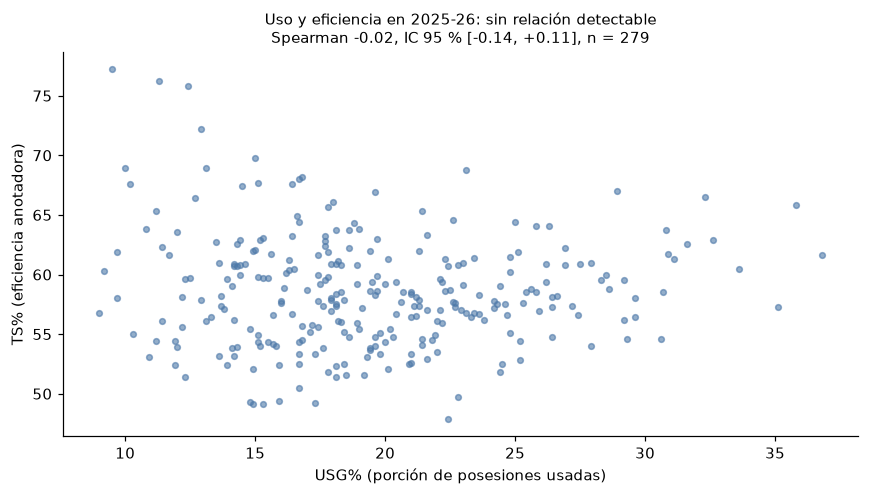

Controlando por REB% (los pívots de bajo uso anotan cerca del aro): -0.003 [-0.122, +0.118]


In [3]:
rho, lo, hi = rank_correlation(pool["usg_pct"], pool["ts_pct"])
rho_c, lo_c, hi_c = rank_correlation(pool["usg_pct"], pool["ts_pct"], control=pool["reb_pct"])
verdict = {
    "none": "sin relación detectable",
    "negative": "más uso, menos eficiencia",
    "positive": "más uso, más eficiencia",
}[correlation_direction(lo, hi)]

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(pool["usg_pct"] * 100, pool["ts_pct"] * 100, s=14, color="#4C78A8", alpha=0.6)
ax.set_xlabel("USG% (porción de posesiones usadas)")
ax.set_ylabel("TS% (eficiencia anotadora)")
ax.set_title(
    f"Uso y eficiencia en {SEASON}: {verdict}\n"
    f"Spearman {rho:+.2f}, IC 95 % [{lo:+.2f}, {hi:+.2f}], n = {len(pool)}",
    fontsize=10,
)
plt.tight_layout()
plt.show()
print(
    f"Controlando por REB% (los pívots de bajo uso anotan cerca del aro): {rho_c:+.3f} [{lo_c:+.3f}, {hi_c:+.3f}]"
)

   usg_pct_mean   n  ts_pct_mean  ci_low  ci_high
0         0.126  56        0.600   0.584    0.616
1         0.163  58        0.583   0.569    0.596
2         0.187  53        0.581   0.570    0.592
3         0.219  56        0.575   0.565    0.584
4         0.277  56        0.591   0.581    0.600


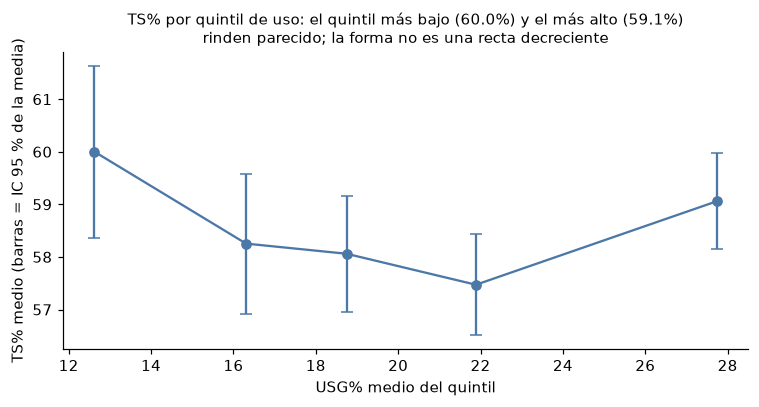

In [4]:
bins = binned_means(pool, "usg_pct", "ts_pct")
print(bins.to_string())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(
    bins["usg_pct_mean"] * 100,
    bins["ts_pct_mean"] * 100,
    yerr=[
        (bins["ts_pct_mean"] - bins["ci_low"]) * 100,
        (bins["ci_high"] - bins["ts_pct_mean"]) * 100,
    ],
    marker="o",
    color="#4C78A8",
    capsize=4,
)
low_q, high_q = bins["ts_pct_mean"].iloc[0], bins["ts_pct_mean"].iloc[-1]
ax.set_title(
    f"TS% por quintil de uso: el quintil más bajo ({low_q:.1%}) y el más alto ({high_q:.1%})\n"
    "rinden parecido; la forma no es una recta decreciente",
    fontsize=10,
)
ax.set_xlabel("USG% medio del quintil")
ax.set_ylabel("TS% medio (barras = IC 95 % de la media)")
plt.tight_layout()
plt.show()

### ¿Se sostiene en otras temporadas?

Una sola temporada puede ser casualidad. Repito el cálculo en 2021-22 a 2025-26, con y sin controlar por REB%.

 season             kind   n    rho    low   high
2021-22      sin control 272 -0.143 -0.244 -0.030
2021-22 controlando REB% 272 -0.153 -0.254 -0.042
2022-23      sin control 263 -0.072 -0.205  0.053
2022-23 controlando REB% 263 -0.061 -0.185  0.069
2023-24      sin control 266 -0.055 -0.164  0.066
2023-24 controlando REB% 266 -0.056 -0.169  0.062
2024-25      sin control 270 -0.036 -0.149  0.076
2024-25 controlando REB% 270 -0.031 -0.148  0.081
2025-26      sin control 279 -0.016 -0.137  0.103
2025-26 controlando REB% 279 -0.003 -0.125  0.117


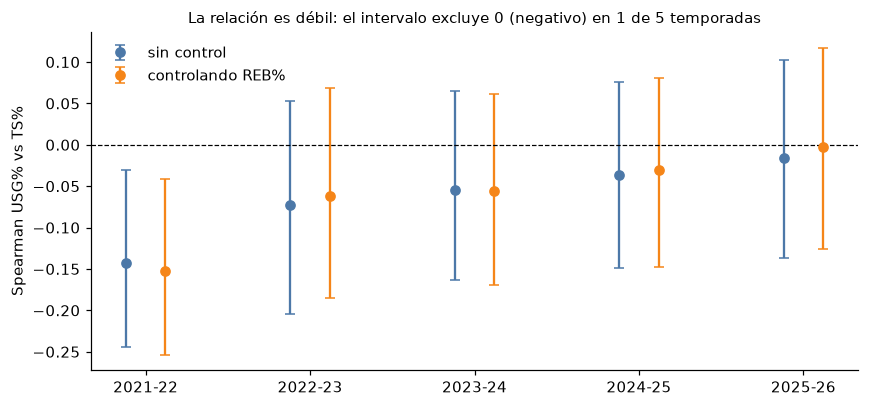

In [5]:
rows = []
for season in STABILITY:
    p = eligible_pool(players[players["season"] == season])
    for label, ctl in (("sin control", None), ("controlando REB%", p["reb_pct"])):
        r, low, high = rank_correlation(p["usg_pct"], p["ts_pct"], control=ctl, n_boot=1000)
        rows.append(
            {"season": season, "kind": label, "n": len(p), "rho": r, "low": low, "high": high}
        )
stab = pd.DataFrame(rows)
print(stab.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.8))
for offset, (kind, color) in zip(
    (-0.12, 0.12), (("sin control", "#4C78A8"), ("controlando REB%", "#F58518")), strict=True
):
    d = stab[stab["kind"] == kind]
    x = np.arange(len(d)) + offset
    ax.errorbar(
        x,
        d["rho"],
        yerr=[d["rho"] - d["low"], d["high"] - d["rho"]],
        fmt="o",
        color=color,
        capsize=3,
        label=kind,
    )
ax.axhline(0, color="k", lw=0.8, ls="--")
ax.set_xticks(range(len(STABILITY)), STABILITY)
ax.set_ylabel("Spearman USG% vs TS%")
n_neg = int((stab[stab["kind"] == "sin control"]["high"] < 0).sum())
ax.set_title(
    f"La relación es débil: el intervalo excluye 0 (negativo) en {n_neg} de {len(STABILITY)} temporadas",
    fontsize=10,
)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Lectura de A.** En 2025-26 no hay relación detectable (ρ ≈ 0, intervalo que incluye 0). En 2021-22 sí aparece una relación débilmente negativa, y desde entonces el valor se acerca a 0. Lo más honesto que se puede decir: *entre jugadores de rotación, el uso explica muy poco de la eficiencia*, y la relación negativa clásica ("el impuesto del uso") es, como mucho, débil.

**Lo que esto NO dice:**
- No dice que subirle el uso a un mismo jugador sea gratis. Los jugadores de alto uso son los mejores anotadores y enfrentan las mejores defensas (se corrige en parte, no del todo); aquí comparo *entre* jugadores.
- Controlar por REB% es un parche para "es un pívot que anota cerca del aro". No hay posiciones en estos datos.
- Cinco temporadas no son cinco muestras independientes de un mismo fenómeno (mismos jugadores varios años).

## 2. Hipótesis C: net rating vs. PIE

**Qué es cada uno.** *Net rating* = puntos anotados menos recibidos por 100 posesiones **del equipo** con el jugador en cancha. Depende de los compañeros y rivales con quienes comparte minutos. *PIE* = porción de los eventos del box score del partido (puntos, rebotes, asistencias, robos, tapones, pérdidas, tiros fallados...) que le corresponden a él. Miden cosas distintas, así que no esperaría una coincidencia perfecta; lo que se pregunta es cuánta.

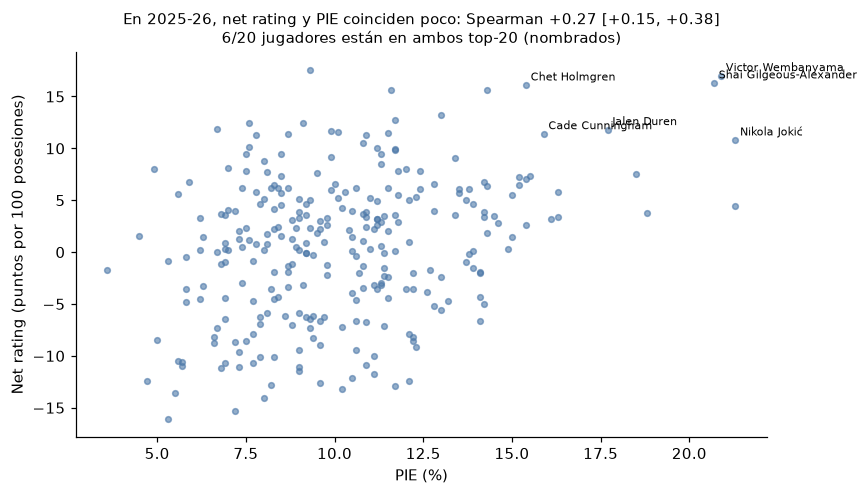

In [6]:
rho, lo, hi = rank_correlation(pool["net_rating"], pool["pie"])
n_shared, shared = top_overlap(pool, "net_rating", "pie", n=20)
word = (
    "coinciden poco" if abs(rho) < 0.3 else "coinciden en parte" if abs(rho) < 0.6 else "coinciden"
)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(pool["pie"] * 100, pool["net_rating"], s=14, color="#4C78A8", alpha=0.6)
for name in shared:
    row = pool[pool["player"] == name].iloc[0]
    ax.annotate(
        name,
        (row["pie"] * 100, row["net_rating"]),
        fontsize=7,
        xytext=(3, 3),
        textcoords="offset points",
    )
ax.set_xlabel("PIE (%)")
ax.set_ylabel("Net rating (puntos por 100 posesiones)")
ax.set_title(
    f"En {SEASON}, net rating y PIE {word}: Spearman {rho:+.2f} [{lo:+.2f}, {hi:+.2f}]\n"
    f"{n_shared}/20 jugadores están en ambos top-20 (nombrados)",
    fontsize=10,
)
plt.tight_layout()
plt.show()

In [7]:
pct = percentile_profile(pool, pool, ["net_rating", "pie"])
gap = (pct["net_rating"] - pct["pie"]).rename("gap")
view = (
    pool[["player", "team", "minutes", "net_rating", "pie"]].join(pct.add_suffix("_pct")).join(gap)
)
view = view.round(
    {"minutes": 0, "net_rating": 1, "pie": 3, "net_rating_pct": 0, "pie_pct": 0, "gap": 0}
)
print("Net rating muy por encima de su PIE:")
print(view.nlargest(6, "gap").to_string(index=False))
print("\nPIE muy por encima de su net rating:")
print(view.nsmallest(6, "gap").to_string(index=False))

Net rating muy por encima de su PIE:
         player team  minutes  net_rating   pie  net_rating_pct  pie_pct    gap
  Hugo González  BOS 1080.000      11.900 0.067          96.000    9.000 87.000
  Luguentz Dort  OKC 1849.000       8.000 0.049          88.000    1.000 87.000
   Marcus Smart  LAL 1767.000       6.800 0.059          84.000    6.000 78.000
  Cason Wallace  OKC 2048.000      12.400 0.076          97.000   20.000 77.000
  Landry Shamet  NYK 1173.000       8.100 0.070          88.000   13.000 75.000
Christian Braun  DEN 1399.000      10.100 0.076          92.000   20.000 73.000

PIE muy por encima de su net rating:
            player team  minutes  net_rating   pie  net_rating_pct  pie_pct     gap
         Alex Sarr  WAS 1306.000     -12.400 0.121           3.000   77.000 -74.000
Michael Porter Jr.  BKN 1690.000      -6.600 0.141          17.000   89.000 -72.000
       Nic Claxton  BKN 1918.000     -12.900 0.117           2.000   74.000 -72.000
 Marvin Bagley III  DAL 1200.

**Lectura de C.** La coincidencia es parcial: ρ ≈ +0.27 con un intervalo que excluye 0 (hay relación) pero lejos de 1, y solo 6 de 20 jugadores están en ambos top-20. Es coherente con que el net rating mezcle al jugador con su equipo.

**Cuidado con la historia que cuento.** Las dos tablas de arriba sugieren un patrón (jugadores de rol en equipos ganadores con net rating alto; jugadores con buenos números en equipos malos con net rating bajo), pero es una *hipótesis* que estos datos no prueban: para separar jugador de compañeros hacen falta datos de alineaciones (Módulo 7, lineups) o modelos tipo RAPM. Tampoco sé si PIE o net rating "tiene razón".

## 3. El radar: percentiles, no valores crudos

Seis ejes con unidades distintas (TS% ≈ 0.57, net rating ≈ -2 puntos...) no se pueden dibujar juntos tal cual. Convierto cada valor en su **percentil** dentro del grupo de ≥ 1000 minutos (empates por la mitad). Ventaja: se lee igual en todos los ejes y los valores extremos no aplastan al resto. Costo: se pierde la magnitud (dos jugadores en el percentil 98 pueden estar lejos entre sí), por eso la página de Streamlit muestra además la tabla de valores crudos.

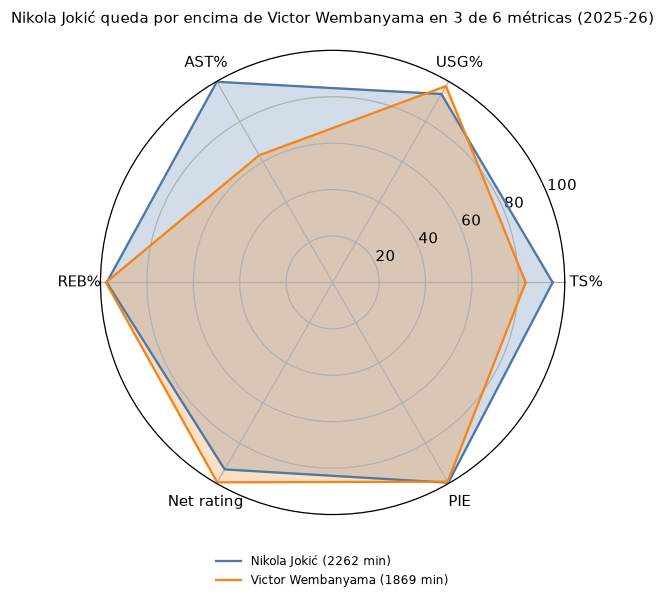

           player team  gp  minutes  ts_pct  usg_pct  ast_pct  reb_pct  net_rating   pie
     Nikola Jokić  DEN  65 2262.000   0.670    0.289    0.458    0.185      10.800 0.213
Victor Wembanyama  SAS  64 1868.800   0.626    0.316    0.170    0.186      17.000 0.209


In [8]:
top = pool[pool["minutes"] >= 1500].nlargest(2, "pie").reset_index(drop=True)
prof = percentile_profile(top, pool)
labels = [RADAR_METRICS[m] for m in prof.columns]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
ahead = int((prof.iloc[0] > prof.iloc[1]).sum())

fig, ax = plt.subplots(figsize=(5.6, 5.6), subplot_kw={"projection": "polar"})
for i, color in enumerate(("#4C78A8", "#F58518")):
    r = prof.iloc[i].tolist()
    ax.plot(
        [*angles, angles[0]],
        [*r, r[0]],
        color=color,
        label=f"{top['player'][i]} ({top['minutes'][i]:.0f} min)",
    )
    ax.fill([*angles, angles[0]], [*r, r[0]], color=color, alpha=0.25)
ax.set_xticks(angles, labels)
ax.set_ylim(0, 100)
ax.set_title(
    f"{top['player'][0]} queda por encima de {top['player'][1]} en {ahead} de {len(labels)} métricas "
    f"({SEASON})",
    fontsize=10,
    pad=18,
)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.18), frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
print(top[["player", "team", "gp", "minutes", *RADAR_METRICS]].round(3).to_string(index=False))

## 4. Resultado vs. hipótesis

No hubo hipótesis previa que confirmar o refutar. Los resultados contra la referencia "sin relación":

| Pregunta | Resultado 2025-26 | Veredicto |
|---|---|---|
| A. Uso vs. eficiencia | ρ ≈ -0.02 [-0.14, +0.10], n = 279 | No se distingue de cero; en 2021-22 fue débilmente negativa |
| C. Net rating vs. PIE | ρ ≈ +0.27 [+0.15, +0.38], 6/20 en común | Relación real pero parcial |

**Qué mejorar (no hecho):** usar posiciones o tipo de jugador para comparar "iguales con iguales"; PER/BPM desde Basketball Reference para contrastar con PIE; datos de alineaciones para separar al jugador de sus compañeros.

## 5. Tus ejercicios

1. **Predice y mide.** Sube el umbral de minutos del grupo a 2000. Antes de correr, escribe si esperas que la relación uso-eficiencia (A) se haga más negativa, más positiva o igual, y por qué. Luego mídelo con `rank_correlation` y mira si el intervalo cambió de lado.
2. **El radar bajo la lupa.** Elige dos jugadores que conozcas y predice en cuántas de las 6 métricas gana el primero. Verifícalo en la página del comparador. ¿Cambia el resultado si usas 500 min en vez de 1000 como mínimo? Si cambia, explica por qué un percentil depende del grupo contra el que se calcula.